# 02 — Demand, and what the KPIs really measure

Two subjects that belong together: where passengers come from, and how the
service they get is scored.

The second half of this notebook is the most important thing in this folder
to read before quoting any number from the others. Every KPI here can be
improved by *serving fewer people*, and knowing exactly how is the difference
between reporting a result and believing one.

Runtime: about two minutes.

In [1]:
# --- Bootstrap ------------------------------------------------------------
# This notebook imports the project as `src.…`, which requires the repository
# root on the import path. `./jupyter-run.sh` puts it there; opening the file
# any other way does not. This cell finds the root by walking up from the
# working directory, so the notebook runs wherever it is launched from and
# whatever folder it sits in.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Seeded runs only reproduce when Python's string hashing is pinned: several
# policies break ties with min() over a set, whose iteration order is
# randomised per process otherwise. The simulation refuses to run unpinned;
# this says so now rather than after a long cell.
if os.environ.get("PYTHONHASHSEED") in (None, "random"):
    print("WARNING: PYTHONHASHSEED is not pinned, so seeded runs will be "
          "refused.\n         Launch with ./jupyter-run.sh, or set "
          "PYTHONHASHSEED=0.")

print(f"repository root: {ROOT}")

repository root: /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus


In [2]:
import os

# How much work this notebook does. Every notebook in this folder has this
# switch and honours the AUTOBUS_SCALE environment variable, so nothing here
# needs editing to run it bigger or smaller.
#
#   "quick"  the default: minutes, same conclusions, wider error bars
#   "full"   the sample sizes behind the figures in the submitted documents
#   "smoke"  a tiny end-to-end check that the notebook runs at all
#
# The outputs saved in this file were produced at "full".
SCALE = os.environ.get("AUTOBUS_SCALE", "quick")
print(f"running at SCALE = {SCALE!r}")

running at SCALE = 'quick'


In [3]:
from tqdm.auto import tqdm

from src.experiment import run_trial


def run_with_progress(desc, total=..., **settings):
    """
    Run one trial with a progress bar over requests settled.

    A single long trial otherwise prints nothing at all until it finishes.
    The observer is a plain callback, deliberately excluded from a run's
    stored identity — watching a run cannot change which run it is.
    :param desc: Label shown on the bar. 
    :param total: Requests the bar counts up to. Defaults to
        ``max_requests``; pass None when the run will be cut off before the
        generator has emitted them all, so the bar counts rather than
        pretending to know how far along it is.
    :param settings: Everything ``run_trial`` takes.
    :return: The TrialResult.
    """
    if total is ...:
        total = settings.get("max_requests")
    bar = tqdm(total=total, desc=desc, unit="req")
    seen = {"settled": 0}

    def observe(progress):
        """Move the bar whenever another request reaches a final state."""
        # Refreshing every tick would cost more than the simulation does: a
        # run is thousands of ticks and at most a few hundred requests.
        if progress.settled == seen["settled"]:
            return
        seen["settled"] = progress.settled
        bar.n = progress.settled
        # refresh=False, then one refresh: set_postfix_str redraws by
        # default, which would render every update twice.
        bar.set_postfix_str(f"{progress.sim_time / 60:.0f} min simulated, "
                            f"{progress.pending} waiting", refresh=False)
        bar.refresh()

    try:
        return run_trial(on_tick=observe, **settings)
    finally:
        bar.close()

In [4]:
import matplotlib.pyplot as plt
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

## 1. A request, and the four things that can happen to it

A `Request` is a passenger: a pickup stop, a dropoff stop, and the time they
asked. It moves through a small lifecycle, and every KPI is computed from the
timestamps it collects on the way.

```
PENDING ──boards──> ON_BUS ──alights──> FULFILLED
   │
   └── waited too long ──> CANCELLED
```

`RequestPool` is the single shared store. The demand generator adds to it,
the bus agent moves requests between states, and the metrics tracker reads
it — nobody keeps a second copy.

In [5]:
from src.algorithm.RequestPool import Request, RequestPool, RequestState

# In a real run the bus agent drives these transitions and stamps the times.
# Doing it by hand here shows what a KPI is actually computed from.
pool = RequestPool()
pool.add(Request(id="r1", pickup_stop_id="library",
                 dropoff_stop_id="gate", created_at=0.0))
ride = pool.get("r1")
print(f"created            {ride.state.name}")

ride.boarded_at = 120.0
pool.update_state("r1", RequestState.ON_BUS)
print(f"bus arrives        {ride.state.name}")

ride.fulfilled_at = 400.0
pool.update_state("r1", RequestState.FULFILLED)
print(f"passenger alights  {ride.state.name}")

print(f"\nwait    = boarded_at - created_at   = "
      f"{ride.boarded_at - ride.created_at:.0f} s")
print(f"ride    = fulfilled_at - boarded_at = "
      f"{ride.fulfilled_at - ride.boarded_at:.0f} s")
print(f"journey = fulfilled_at - created_at = "
      f"{ride.fulfilled_at - ride.created_at:.0f} s")

# The pool is indexed by state, so "who is waiting" is a lookup, not a scan.
print(f"\npool now holds: {len(pool.get_fulfilled())} fulfilled, "
      f"{len(pool.get_pending())} pending")

created            PENDING
bus arrives        ON_BUS
passenger alights  FULFILLED

wait    = boarded_at - created_at   = 120 s
ride    = fulfilled_at - boarded_at = 280 s
journey = fulfilled_at - created_at = 400 s

pool now holds: 1 fulfilled, 0 pending


## 2. Where demand comes from

`DemandGenerator` is asked on every tick how many requests to create, and
delegates that decision to a `GenerationPolicy`. The one used throughout is
`PeriodicPolicy`: one request every `interval_s` seconds, up to
`max_requests` in total, then it stops.

Deliberately simple. The demand *rate* is the experimental variable in
notebook 06, and a simple generator makes that rate exactly what it says it
is rather than something drawn from a distribution.

In [6]:
from src.map.graph import PlanarStreetGraph
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.simulation.DemandGenerator import DemandGenerator, PeriodicPolicy

CAMPUS = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
              stop_density=0.5)
graph = TransitGraph(PlanarMapProvider(PlanarStreetGraph.generate(**CAMPUS)))

import random
random.seed(0)

demand_pool = RequestPool()
generator = DemandGenerator(
    pool=demand_pool,
    policy=PeriodicPolicy(interval_s=60.0, max_requests=5),
    stops=graph.get_stops(),
)

for tick in range(0, 400, 10):          # 10-second ticks
    generator.update(float(tick))

for request in demand_pool.get_all():
    print(f"  t={request.created_at:>5.0f}s   "
          f"{request.pickup_stop_id}  ->  {request.dropoff_stop_id}")
print(f"\nexhausted: {generator.is_exhausted()}")

  t=    0s   13_14  ->  12_9
  t=   60s   7_3  ->  3_7
  t=  120s   9_12  ->  7_3
  t=  180s   12_11  ->  5_6
  t=  240s   9_12  ->  10_11

exhausted: True


### Demand does not have to be uniform

`DemandGenerator` takes optional per-stop `weights`, which is how a hotspot —
a station, a lecture hall at the end of a class — is expressed. Every
experiment in this project uses uniform demand, because a hotspot makes the
map easier in a way that flatters demand-responsive routing, and the honest
comparison is the one that does not.

In [7]:
hot_stop = graph.get_stops()[0].edge.id

random.seed(0)
weighted_pool = RequestPool()
weighted = DemandGenerator(
    pool=weighted_pool,
    policy=PeriodicPolicy(interval_s=60.0, max_requests=40),
    stops=graph.get_stops(),
    weights={s.edge.id: (20.0 if s.edge.id == hot_stop else 1.0)
             for s in graph.get_stops()},
)
for tick in range(0, 2500, 10):
    weighted.update(float(tick))

touching_hotspot = sum(
    1 for r in weighted_pool.get_all()
    if hot_stop in (r.pickup_stop_id, r.dropoff_stop_id))
print(f"{touching_hotspot} of {len(weighted_pool.get_all())} requests touch "
      f"the weighted stop (1 stop out of {len(graph.get_stops())})")

27 of 40 requests touch the weighted stop (1 stop out of 21)


## 3. Patience — the constraint that shapes everything

A waiting passenger does not wait forever. `max_wait_s` is how long they will
stand at the stop before giving up; a request that reaches it becomes
`CANCELLED` and is never served.

This single parameter decides what kind of problem the bus is solving:

- **Impatient** (`max_wait_s = 900`, the usual setting): the queue is capped
  by abandonment. The bus cannot fall arbitrarily far behind, because demand
  it cannot reach removes itself.
- **Patient** (`max_wait_s = None`): nobody ever gives up, so every request
  is eventually served and the queue can grow without bound.

Both are used. The impatient regime is the realistic one; the patient one is
where overload becomes visible instead of being hidden by cancellations.

In [8]:
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy

PATIENCES = [300.0, 600.0, 900.0, 1350.0, 1800.0]

# Requests per trial. More demand makes the effect below cleaner; it does not
# change its direction.
REQUESTS = {"smoke": 20, "quick": 100, "full": 200}[SCALE]

rows = []
# Nested bars: the outer one counts settings, the inner one counts the
# requests of the trial currently running.
for patience in tqdm(PATIENCES, desc="patience sweep", unit="setting"):
    result = run_with_progress(
        f"  patience {patience:.0f} s",
        policy_factory=lambda g: ReorderingInsertionPolicy(g, max_wait_s=900.0),
        graph=PlanarStreetGraph.generate(**CAMPUS),
        seed=0, max_requests=REQUESTS, demand_interval_s=60.0, capacity=40,
        max_wait_s=patience, silent=True,
    )
    rows.append({
        "patience (s)": patience,
        "served": f"{result.kpi.served_fraction:.1%}",
        "mean wait (s)": round(result.kpi.mean_wait_time),
        "mean ride (s)": round(result.kpi.mean_ride_time),
        "cancelled": result.kpi.cancelled_count,
    })

import pandas as pd
display(pd.DataFrame(rows).set_index("patience (s)"))

patience sweep:   0%|          | 0/5 [00:00<?, ?setting/s]

  patience 300 s:   0%|          | 0/100 [00:00<?, ?req/s]

  patience 600 s:   0%|          | 0/100 [00:00<?, ?req/s]

  patience 900 s:   0%|          | 0/100 [00:00<?, ?req/s]

  patience 1350 s:   0%|          | 0/100 [00:00<?, ?req/s]

  patience 1800 s:   0%|          | 0/100 [00:00<?, ?req/s]

,served,mean wait (s),mean ride (s),cancelled
patience (s),,,,
300.0,46.0%,176,209,54
600.0,74.0%,318,362,26
900.0,94.0%,429,386,6
1350.0,96.0%,447,428,4
1800.0,98.0%,467,397,2


## 4. The KPIs

| KPI | Definition | Watch out for |
|---|---|---|
| `fulfilled_count` / `cancelled_count` | Terminal counts | — |
| `served_fraction` | fulfilled ÷ **everything ever created** | The honest coverage number: still-waiting demand counts against it |
| `fulfillment_rate` | fulfilled ÷ (fulfilled + cancelled) | Ignores requests still pending at the end — flattering on a truncated run |
| `mean_wait_time` | created → boarded, **fulfilled requests only** | Improves when hard passengers are abandoned |
| `p90_wait_time`, `max_wait_time` | The wait tail | The guarantee a fixed route gives for free |
| `mean_ride_time` | boarded → alighted, fulfilled only | Ride-sharing detours land here |
| `mean_journey_time` | created → alighted | wait + ride, the passenger's whole experience |
| `throughput` | fulfilled per simulated minute | The one KPI that punishes abandonment |

## 5. How these KPIs lie

This is the section to read twice.

**Trap 1 — wait and ride are computed over fulfilled requests only.** A
passenger who gives up contributes nothing to the mean wait. So a policy that
abandons its most awkward passengers *looks faster*, and the improvement is
entirely an artefact of who was excluded from the average.

The table in section 3 shows it directly: as patience gets shorter, mean wait
**falls** — not because anyone was served better, but because the slowest
passengers were removed from the sample.

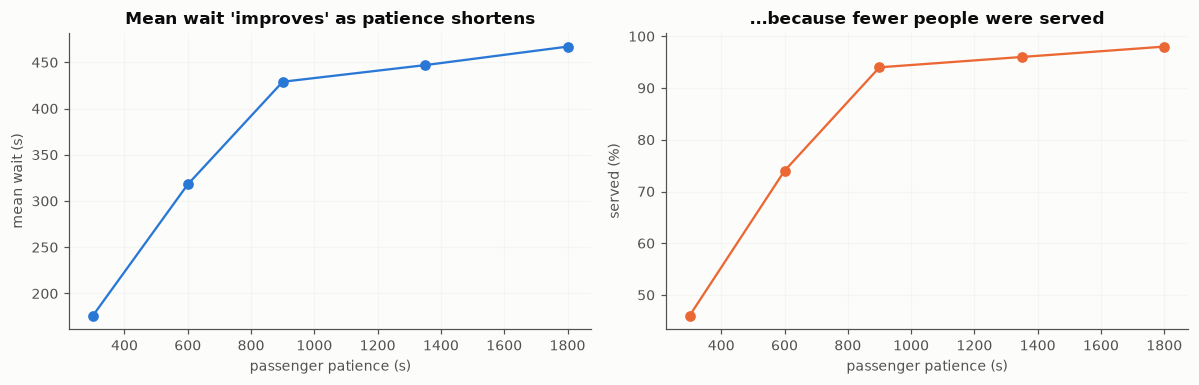

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
frame = pd.DataFrame(rows)
waits = [int(w) for w in frame["mean wait (s)"]]
serves = [float(s.strip("%")) for s in frame["served"]]

axes[0].plot(PATIENCES, waits, marker="o", color=SERIES[0])
axes[0].set_title("Mean wait 'improves' as patience shortens")
axes[0].set_xlabel("passenger patience (s)")
axes[0].set_ylabel("mean wait (s)")

axes[1].plot(PATIENCES, serves, marker="o", color=SERIES[1])
axes[1].set_title("...because fewer people were served")
axes[1].set_xlabel("passenger patience (s)")
axes[1].set_ylabel("served (%)")

for axis in axes:
    axis.grid(alpha=0.3)
figure.tight_layout()

**The rule this forces:** never quote a wait or ride figure
without the served fraction beside it. A comparison between two policies is
only meaningful when they served comparable fractions of the same demand — or
when the difference in coverage is stated as part of the result.

**Trap 2 — `fulfillment_rate` and `served_fraction` are not the same thing.**
`fulfillment_rate` only counts requests that reached a terminal state.
Requests still sitting `PENDING` when the run ends are invisible to it, so a
badly overloaded run — where most demand is still queued — can report a
respectable fulfillment rate. `served_fraction` counts them, which is why it
is the coverage number used everywhere in this project.

In [10]:
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy

OVERLOAD = {"smoke": 60, "quick": 200, "full": 200}[SCALE]

# An overloaded run: demand arrives far faster than one bus can serve it,
# and nobody gives up, so requests pile up PENDING rather than cancelling.
# The clock runs out with demand still queued, which is the state the two
# coverage KPIs disagree about.
overload = run_with_progress(
    "overloaded run",
    # The generator will not get through the whole batch before max_time, so
    # a bar counting up to OVERLOAD would stall short of the end and look
    # broken. Counting is the honest display here.
    total=None,
    # L0 rather than the recommended L1: with nobody giving up, the schedule
    # grows very long and the repair pass makes this cell slow for no gain.
    # What is being shown is what the two KPIs report, not which policy
    # reports it.
    policy_factory=lambda g: WindowInsertionPolicy(g, max_wait_s=900.0),
    graph=PlanarStreetGraph.generate(**CAMPUS),
    seed=0, max_requests=OVERLOAD, demand_interval_s=15.0, capacity=40,
    max_wait_s=None,            # patient: nothing cancels
    max_time=2500.0,            # cut short, leaving demand in the queue
    keep_tick_history=True,     # so the final state can be counted below
    silent=True,
)

# Count what was really in the pool when the clock stopped. Subtracting from
# OVERLOAD instead would be wrong twice over: the generator never emitted the
# whole batch, and riders still aboard are not waiting for a bus.
final = overload.tick_history[-1]
created = (overload.kpi.fulfilled_count + overload.kpi.cancelled_count
           + final.pending_count + final.occupancy)

print(f"fulfillment_rate  {overload.kpi.fulfillment_rate:.1%}   "
      f"<- looks fine")
print(f"served_fraction   {overload.kpi.served_fraction:.1%}   "
      f"<- the truth")
print(f"\nthe generator was asked for {OVERLOAD} requests and emitted "
      f"{created} before the clock stopped at {final.sim_time:.0f} s")
print(f"  fulfilled         {overload.kpi.fulfilled_count}")
print(f"  cancelled         {overload.kpi.cancelled_count}")
print(f"  still waiting     {final.pending_count}")
print(f"  still on the bus  {final.occupancy}")

overloaded run: 0req [00:00, ?req/s]

fulfillment_rate  100.0%   <- looks fine
served_fraction   44.9%   <- the truth

the generator was asked for 200 requests and emitted 167 before the clock stopped at 2500 s
  fulfilled         75
  cancelled         0
  still waiting     52
  still on the bus  40


The breakdown matters as much as the two percentages.

`fulfillment_rate` sees only the requests that reached a terminal state — every
one of which was fulfilled, hence 100%. It cannot see the passengers still
standing at a stop, and under load those are most of the interesting ones.

Note also **what the denominator is**. `served_fraction` is computed over the
requests that were *created*, not over the number the generator was asked for.
This run is cut off by `max_time` with demand still arriving, so the generator
never emitted the whole batch — a request that was never created is not a
request the bus failed to serve, and counting it as one would be its own kind
of dishonest.

**Trap 3 — wait time cannot discriminate when the service
window equals passenger patience.** The insertion policies promise a pickup
within a service window and refuse anyone they cannot reach in time. Set that
window equal to patience — which is the recommended setting — and every
served passenger waited less than the patience by construction, while everyone
who would have waited longer has been cancelled instead.

The result is that mean wait is bounded on *both* arms of the comparison and
stops being able to tell them apart. In that configuration, **coverage is the
KPI that carries the signal**, and wait is nearly a constant. Notebook 08
reports this explicitly for the CARLA campaign rather than plotting a flat
line and calling it a result.

**Trap 4 — a map that is too easy discriminates nothing.** On the 6-stop
version of the campus map (notebook 01), a plain fixed route serves everybody
and every policy ties. A scenario has to be hard enough to separate the arms
before any of these numbers mean anything — which is why the demand rate and
the map size are stated with every result.

## 6. Watching the queue

The per-tick trace is what the KPIs are computed from, and it shows things an
average cannot: whether the bus is keeping up, and whether the queue is
draining or growing.

healthy run:   0%|          | 0/100 [00:00<?, ?req/s]

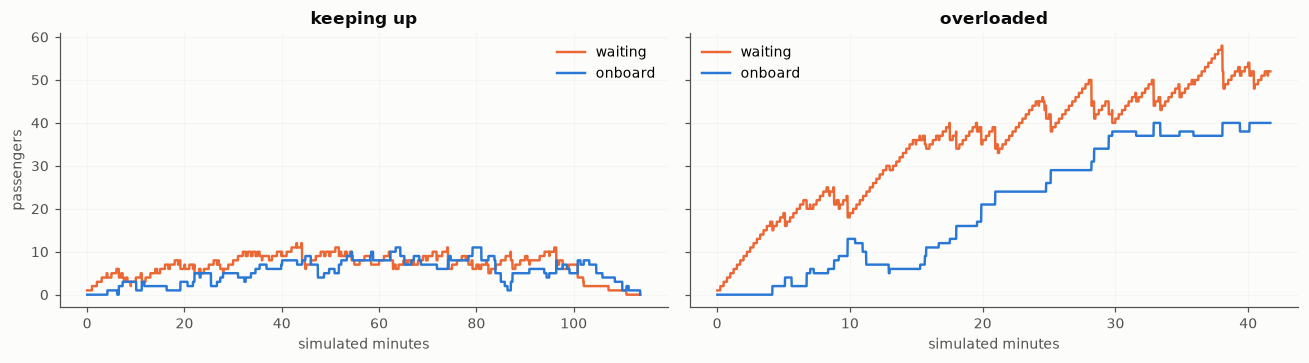

In [11]:
healthy = run_with_progress(
    "healthy run",
    policy_factory=lambda g: ReorderingInsertionPolicy(g, max_wait_s=900.0),
    graph=PlanarStreetGraph.generate(**CAMPUS),
    seed=0, max_requests=REQUESTS, demand_interval_s=60.0, capacity=40,
    max_wait_s=900.0, keep_tick_history=True, silent=True,
)

figure, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for axis, (label, trial) in zip(axes, [("keeping up", healthy),
                                       ("overloaded", overload)]):
    times = [s.sim_time / 60 for s in trial.tick_history]
    axis.plot(times, [s.pending_count for s in trial.tick_history],
              lw=1.6, color=SERIES[1], label="waiting")
    axis.plot(times, [s.occupancy for s in trial.tick_history],
              lw=1.6, color=SERIES[0], label="onboard")
    axis.set_title(label)
    axis.set_xlabel("simulated minutes")
    axis.grid(alpha=0.3)
    axis.legend()
axes[0].set_ylabel("passengers")
figure.tight_layout()

The left panel is a bus in control of its demand: the queue
rises and falls. The right panel is a bus that has lost — the queue climbs and
never comes back, and the seats stay full. Notebook 06 is about finding
exactly where the transition between those two pictures happens.

*(The overloaded run above is patient — nobody gives up — which is why the
queue is free to grow. With the usual 900 s patience the same overload shows
up as cancellations instead, and the pending curve stays deceptively flat.)*

Next: **03 — Policy shootout**, where the routing strategies finally compete.